# Helmet Detection System Using YOLOv8
AIRI Team PITB - AI Internship Task 1

**Before running:** Runtime > Change runtime type > **T4 GPU**. Upload your Roboflow/CVAT YOLO export to
`MyDrive/cv_project/raw_export/` (must contain `images/` and `labels/` folders with all images and matching .txt files).
Run cells top to bottom.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Install Ultralytics and check GPU

In [2]:
!pip install -q -U ultralytics
import torch
print("GPU Available:", torch.cuda.is_available())
!nvidia-smi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.9 MB/s eta 0:00:00
GPU Available: True
Tue Oct 20 08:19:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |

## 3. Settings (edit class names if yours differ)

In [3]:
BASE = "/content/drive/MyDrive/cv_project"
RAW = f"{BASE}/raw_export"        # unzipped Roboflow folder (train/ valid/ test/ inside)
DS = f"{BASE}/dataset"
# IMPORTANT: order must match Roboflow's data.yaml -> names: ['helmet', 'no_helmet', 'person']
CLASSES = ["helmet", "no_helmet", "person"]

## 4. Split dataset 70% train / 20% val / 10% test
Works with the Roboflow export as it is (train/valid/test folders). All images are pooled and re-split randomly.

In [4]:
import os, random, shutil, glob
random.seed(42)
exts = ("jpg","jpeg","png")
imgs = sorted(p for e in exts for p in glob.glob(f"{RAW}/**/images/*.{e}", recursive=True))
labels = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(f"{RAW}/**/labels/*.txt", recursive=True)}
print("Total images found:", len(imgs), "| label files found:", len(labels))
random.shuffle(imgs)
n = len(imgs); n_tr = int(n*0.7); n_va = int(n*0.2)
splits = {"train": imgs[:n_tr], "val": imgs[n_tr:n_tr+n_va], "test": imgs[n_tr+n_va:]}
for s, files in splits.items():
    os.makedirs(f"{DS}/images/{s}", exist_ok=True); os.makedirs(f"{DS}/labels/{s}", exist_ok=True)
    for f in files:
        name = os.path.splitext(os.path.basename(f))[0]
        shutil.copy(f, f"{DS}/images/{s}/")
        if name in labels: shutil.copy(labels[name], f"{DS}/labels/{s}/")
        else: print("Missing label:", name)
    print(s, len(files))

Total images found: 157 | label files found: 157
train 109
val 31
test 17


## 5. Create data.yaml
- `path`: dataset root folder  - `train`: images the model learns from  - `val`: images used to check progress while training
- `test`: images kept for the final fair evaluation  - `names`: class ID to class name

In [5]:
yaml_text = f"""path: {DS}
train: images/train
val: images/val
test: images/test

names:
""" + "\n".join(f"  {i}: {c}" for i, c in enumerate(CLASSES))
open(f"{DS}/data.yaml","w").write(yaml_text)
print(yaml_text)

path: /content/drive/MyDrive/cv_project/dataset
train: images/train
val: images/val
test: images/test

names:
  0: helmet
  1: no_helmet
  2: person


## 6. Validate labels (format, class IDs, 0-1 range)

In [6]:
bad = 0; counts = {i:0 for i in range(len(CLASSES))}
for s in ["train","val","test"]:
    for f in glob.glob(f"{DS}/labels/{s}/*.txt"):
        for ln, line in enumerate(open(f).read().strip().splitlines(), 1):
            p = line.split()
            ok = len(p)==5 and p[0].isdigit() and int(p[0])<len(CLASSES) and all(0<=float(x)<=1 for x in p[1:])
            if ok: counts[int(p[0])]+=1
            else: bad+=1; print("BAD:", f, ln, line)
print("Bad lines:", bad)
print("Boxes per class:", {CLASSES[i]:c for i,c in counts.items()})

Bad lines: 0
Boxes per class: {'helmet': 125, 'no_helmet': 57, 'person': 182}


## 7. Train YOLOv8n (baseline)

In [7]:
import time
from ultralytics import YOLO
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
model = YOLO("yolov8n.pt")
t0 = time.time()
results = model.train(
    data=f"{DS}/data.yaml", epochs=30, imgsz=640, batch=8, pretrained=True,
    project=f"{BASE}/outputs/training_results", name="yolov8n_baseline", exist_ok=True)
mins = (time.time()-t0)/60
print(f"GPU used: {gpu}\nTraining time: {mins:.1f} minutes")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/cv_project/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchsc

## 8. Save best.pt

In [8]:
os.makedirs(f"{BASE}/models", exist_ok=True)
shutil.copy(f"{BASE}/outputs/training_results/yolov8n_baseline/weights/best.pt", f"{BASE}/models/best.pt")
print("Saved best.pt")

Saved best.pt


## 9. Evaluation: validation + test metrics, per-class

In [9]:
import pandas as pd
model = YOLO(f"{BASE}/models/best.pt")
for split in ["val","test"]:
    m = model.val(data=f"{DS}/data.yaml", split=split, imgsz=640, plots=True,
                  project=f"{BASE}/outputs/training_results", name=f"eval_{split}", exist_ok=True)
    print(f"\n=== {split.upper()} ===")
    print(f"Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")
    rows = [{"class": m.names[c], "precision": m.box.p[i], "recall": m.box.r[i],
             "mAP50": m.box.ap50[i], "mAP50-95": m.box.ap[i]} for i, c in enumerate(m.box.ap_class_index)]
    display(pd.DataFrame(rows).round(3))

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 54.8±12.2 MB/s, size: 61.1 KB)
val: Scanning /content/drive/MyDrive/cv_project/dataset/labels/val.cache... 31 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 7.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4it/s 1.4s
                   all         31         80      0.598      0.496      0.553      0.232
                helmet         21         26      0.668      0.577      0.639      0.287
             no_helmet         12         14      0.439      0.286      0.366      0.114
                person         31         40      0.688      0.625      0.654      0.294
Speed: 6.4ms preprocess, 9.7ms inference, 0.0ms loss, 5.5ms postprocess per image
Results saved to /content/drive/MyDrive/c

,class,precision,recall,mAP50,mAP50-95
0,helmet,0.668,0.577,0.639,0.287
1,no_helmet,0.439,0.286,0.366,0.114
2,person,0.688,0.625,0.654,0.294


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 55.1±9.4 MB/s, size: 62.1 KB)
val: Scanning /content/drive/MyDrive/cv_project/dataset/labels/test... 17 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 205.2it/s 0.1s
val: New cache created: /content/drive/MyDrive/cv_project/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.4it/s 0.8s
                   all         17         34      0.585      0.586       0.63      0.312
                helmet         14         14      0.693      0.357       0.57      0.276
             no_helmet          3          3       0.42      0.667      0.607       0.33
                person         17         17      0.641      0.735      0.714      0.329
Speed: 7.5ms preprocess, 14.8ms inference, 0

,class,precision,recall,mAP50,mAP50-95
0,helmet,0.693,0.357,0.570,0.276
1,no_helmet,0.420,0.667,0.607,0.330
2,person,0.641,0.735,0.714,0.329


## 10. Training curves and confusion matrix

results.png


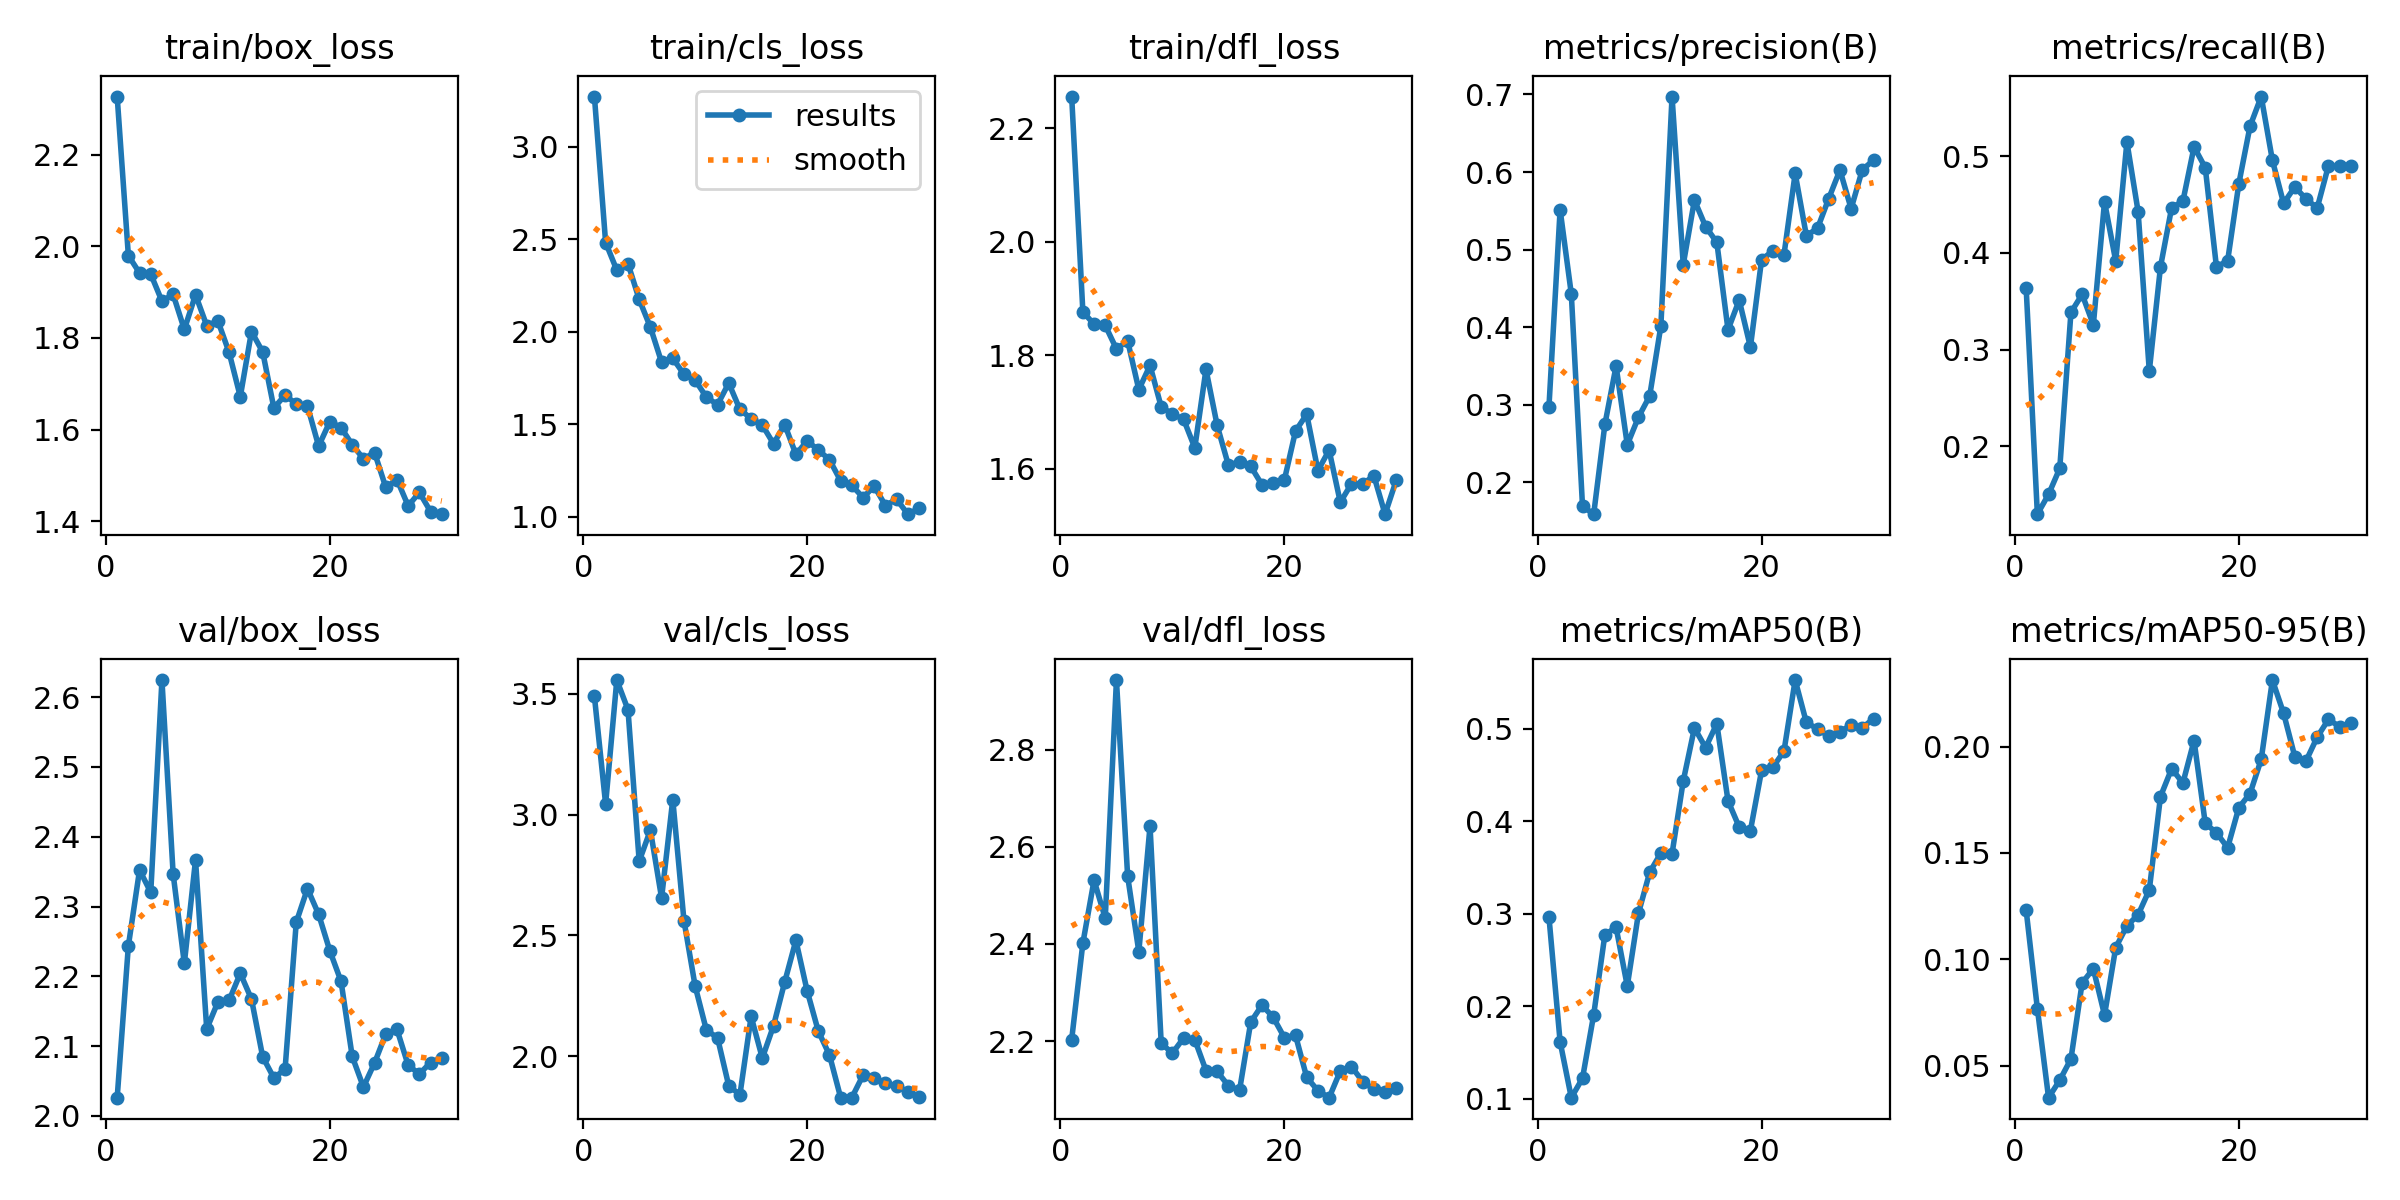

confusion_matrix.png


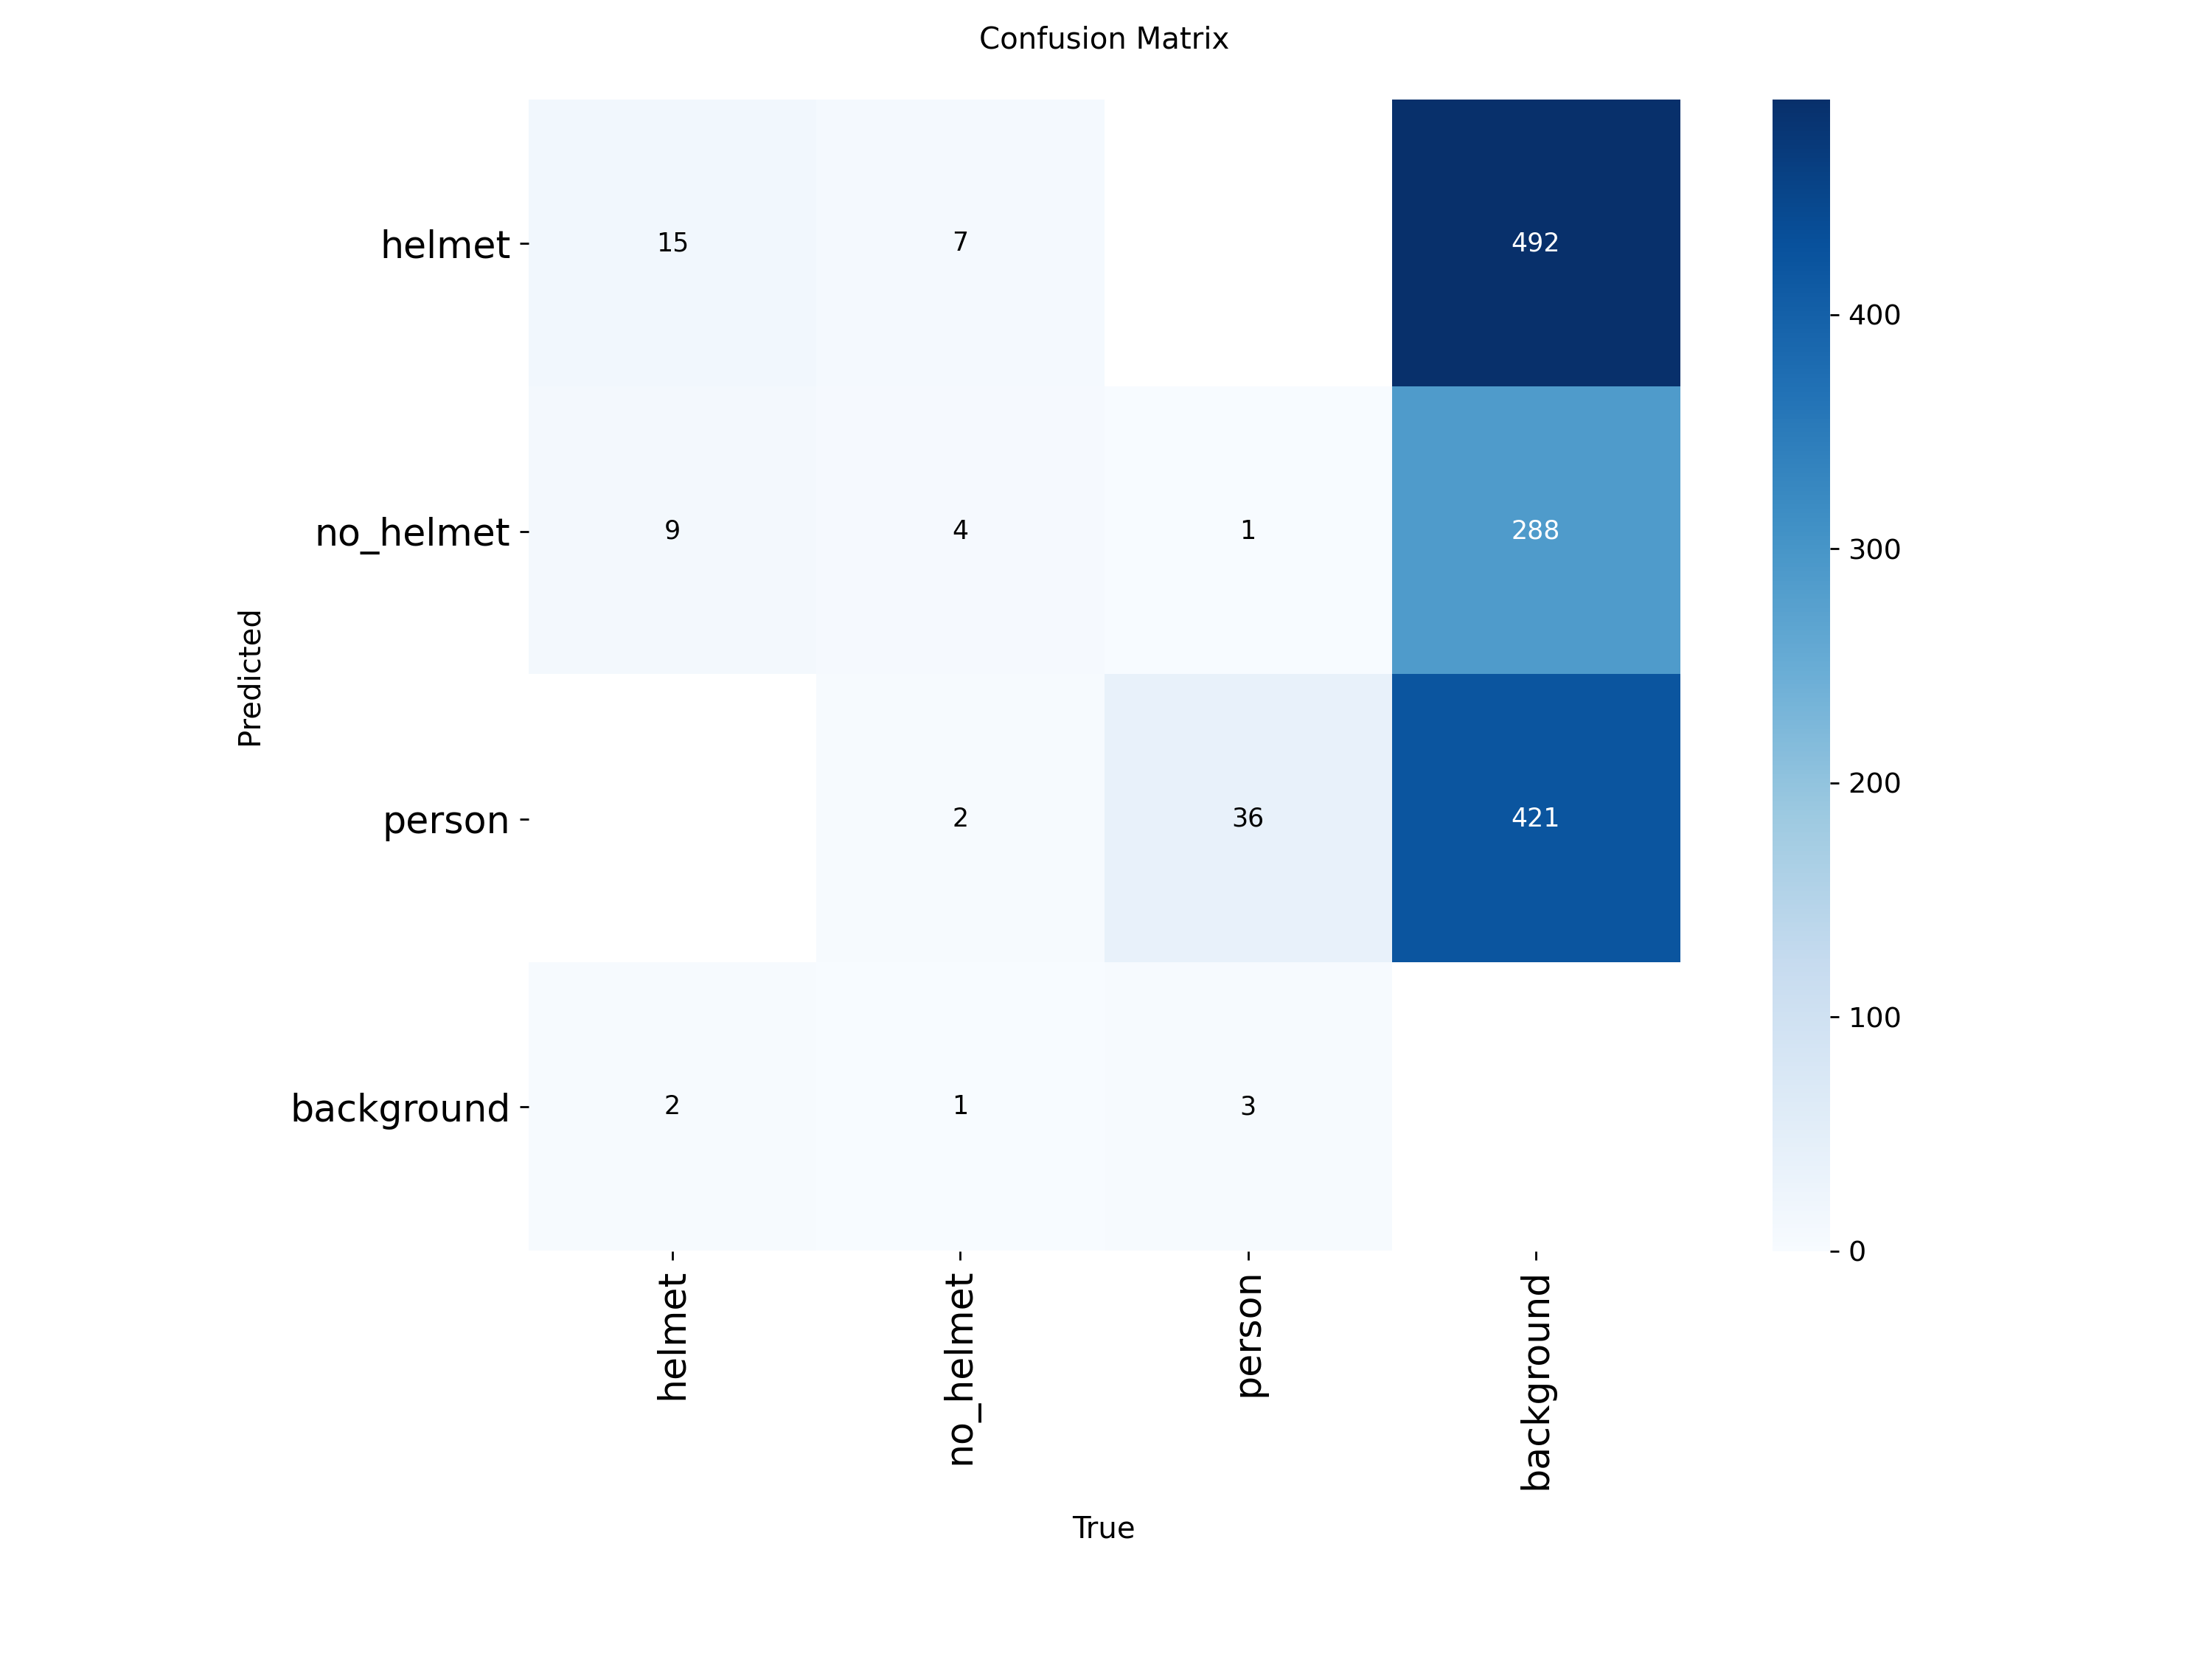

confusion_matrix_normalized.png


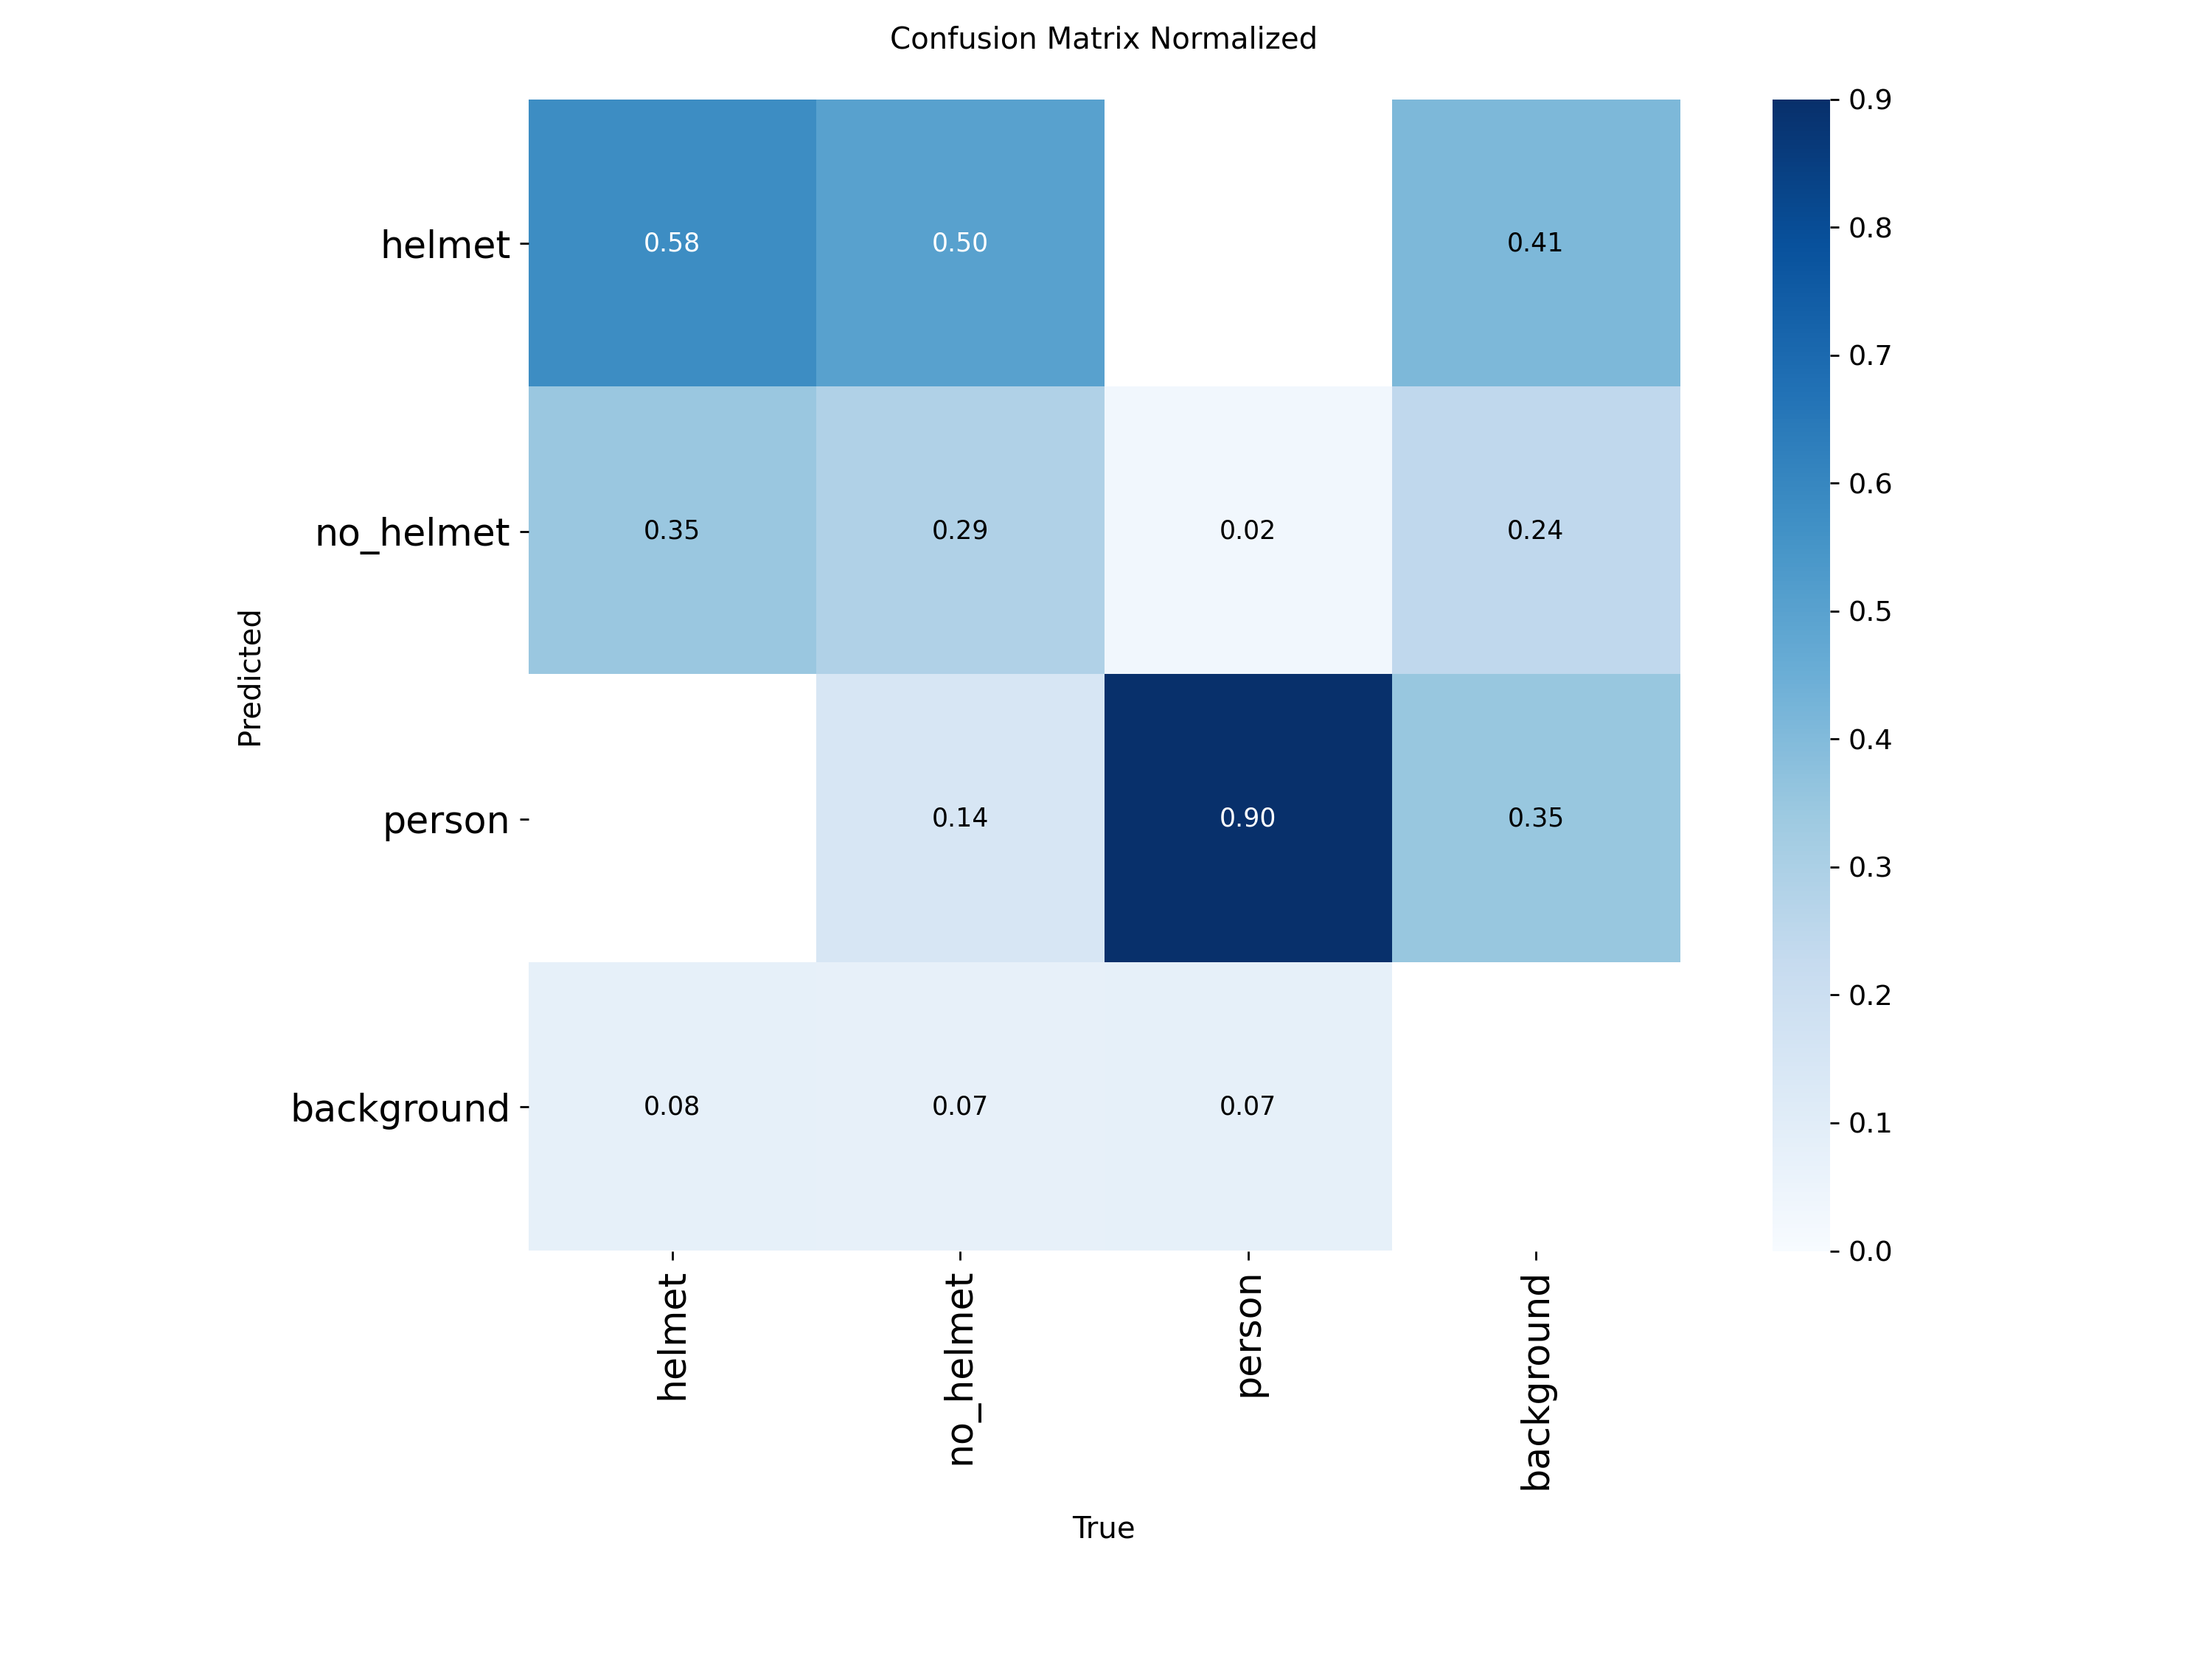

In [10]:
import os
from IPython.display import Image, display

# Redefining BASE path in case previous cells were not run
BASE = "/content/drive/MyDrive/cv_project"
R = f"{BASE}/outputs/training_results/yolov8n_baseline"

for f in ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png", "PR_curve.png"]:
    if os.path.exists(f"{R}/{f}"):
        print(f)
        display(Image(f"{R}/{f}", width=800))

## 11. Inference on unseen test images (conf visible)


image 1/17 /content/drive/MyDrive/cv_project/dataset/images/test/BikesHelmets133_png_jpg.rf.0fffb4d044cce0995e9120622034af9a.jpg: 640x640 1 no_helmet, 12.5ms
image 2/17 /content/drive/MyDrive/cv_project/dataset/images/test/BikesHelmets136_png_jpg.rf.c536bcf6fdfeaa241b458551556b5acf.jpg: 640x640 1 person, 15.3ms
image 3/17 /content/drive/MyDrive/cv_project/dataset/images/test/BikesHelmets139_png_jpg.rf.bfd9e25d7df1967237d9426ec839fb53.jpg: 640x640 1 person, 13.8ms
image 4/17 /content/drive/MyDrive/cv_project/dataset/images/test/BikesHelmets167_png_jpg.rf.35ffdf8e11b0a8c739215cf2e1444125.jpg: 640x640 1 helmet, 1 person, 19.9ms
image 5/17 /content/drive/MyDrive/cv_project/dataset/images/test/BikesHelmets169_png_jpg.rf.40a414563b54016bbd276dab09561430.jpg: 640x640 2 helmets, 1 person, 13.3ms
image 6/17 /content/drive/MyDrive/cv_project/dataset/images/test/BikesHelmets17_png_jpg.rf.dc5c3eda8bbd8199ebdf6eeb6c0d4930.jpg: 640x640 1 person, 13.8ms
image 7/17 /content/drive/MyDrive/cv_project/d

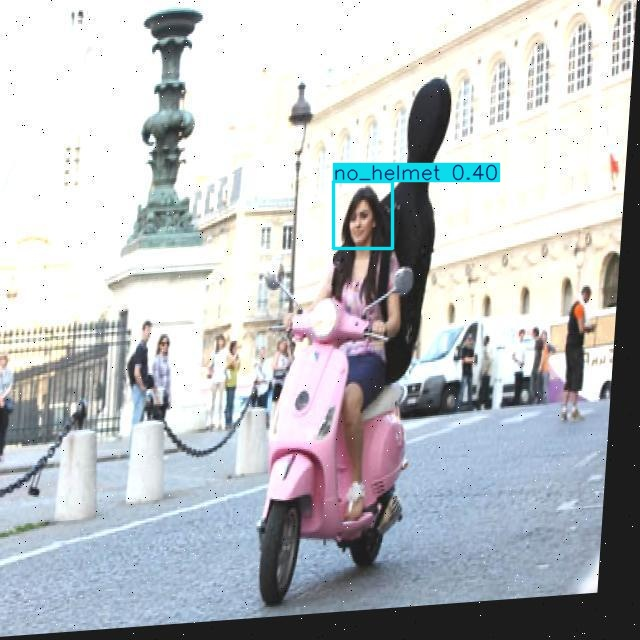

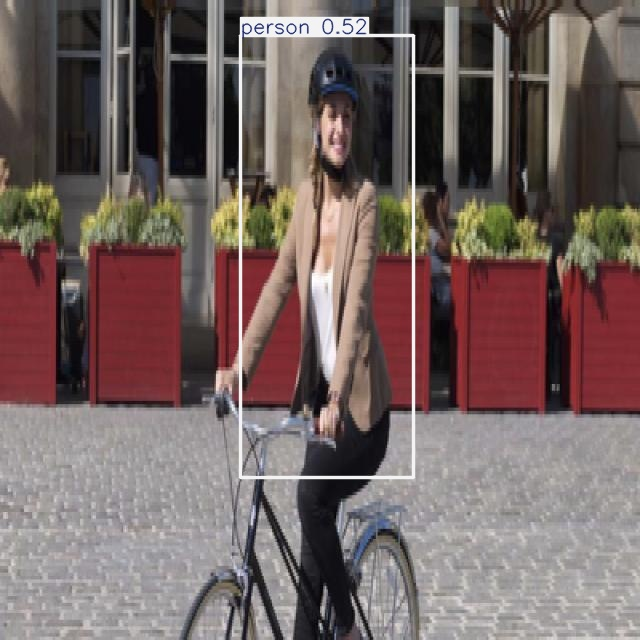

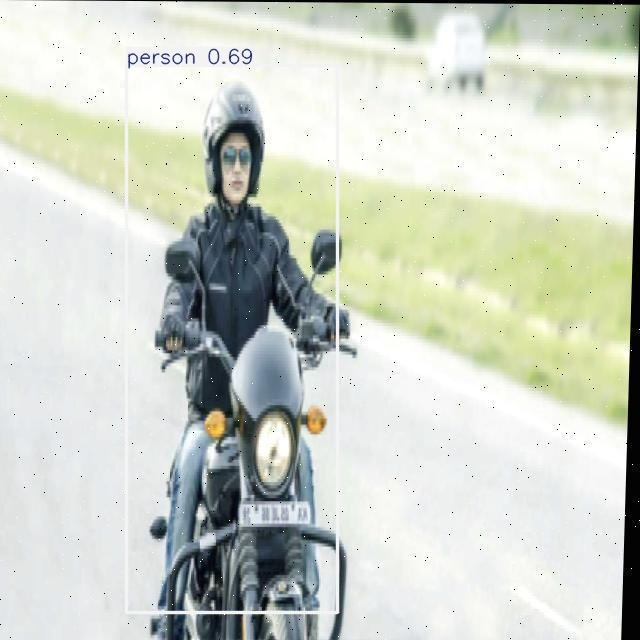

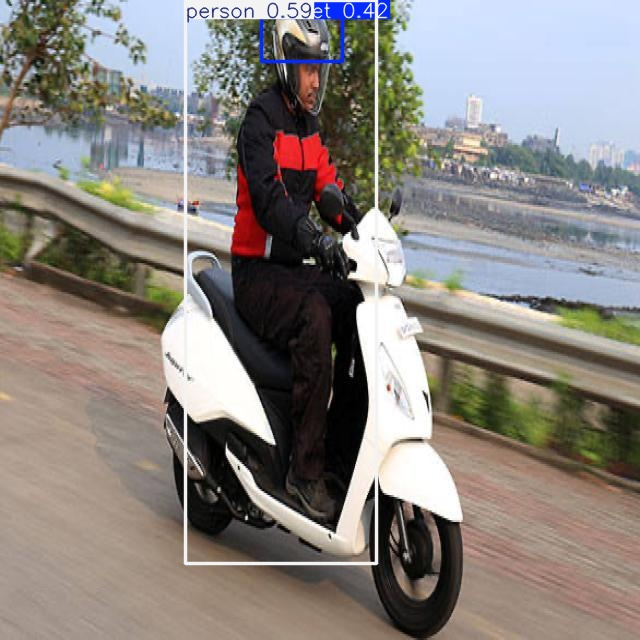

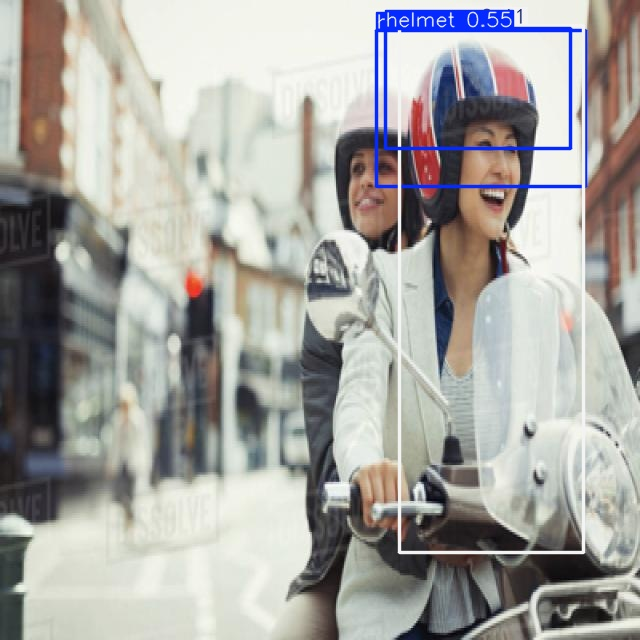

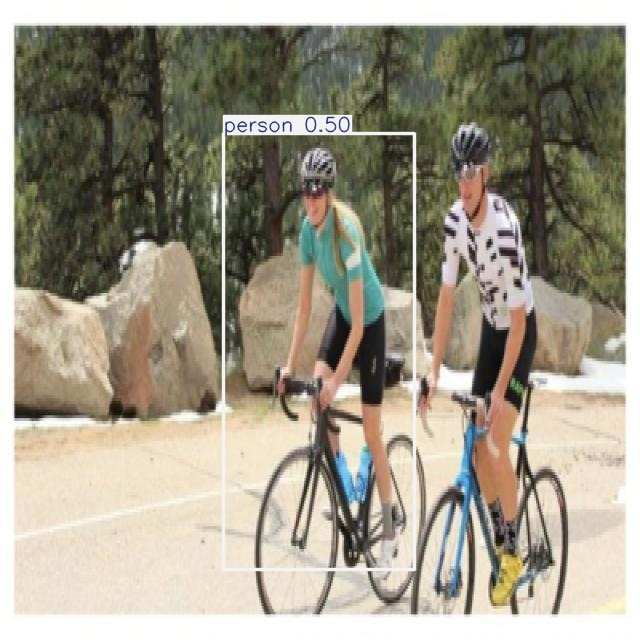

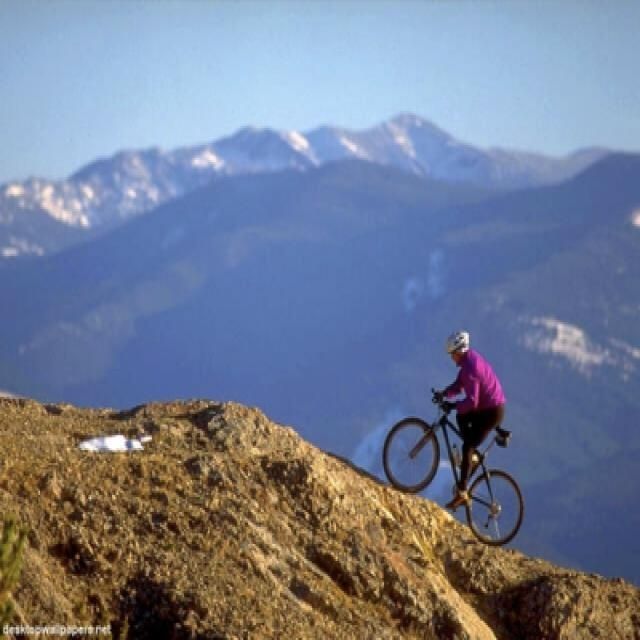

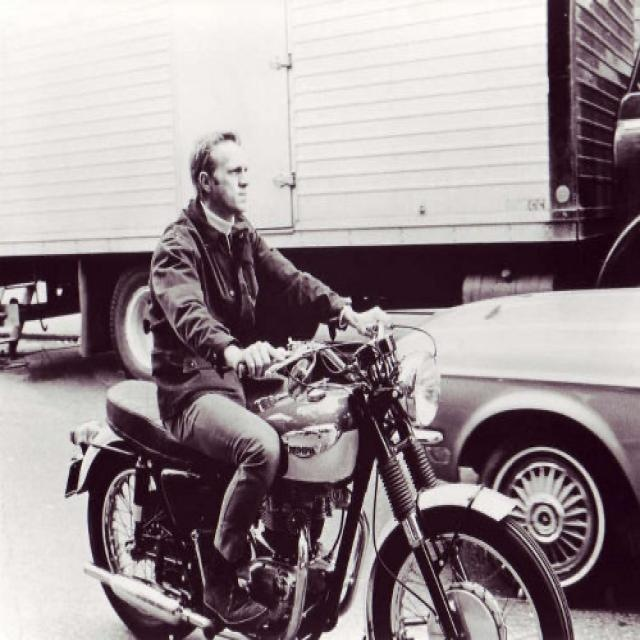

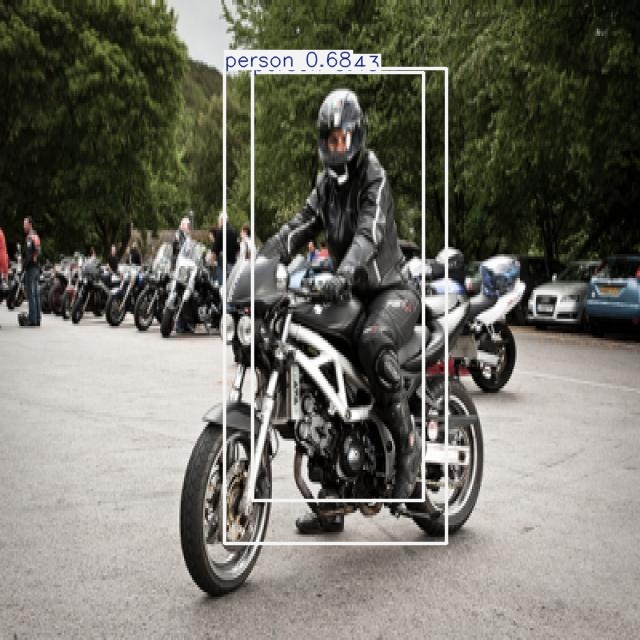

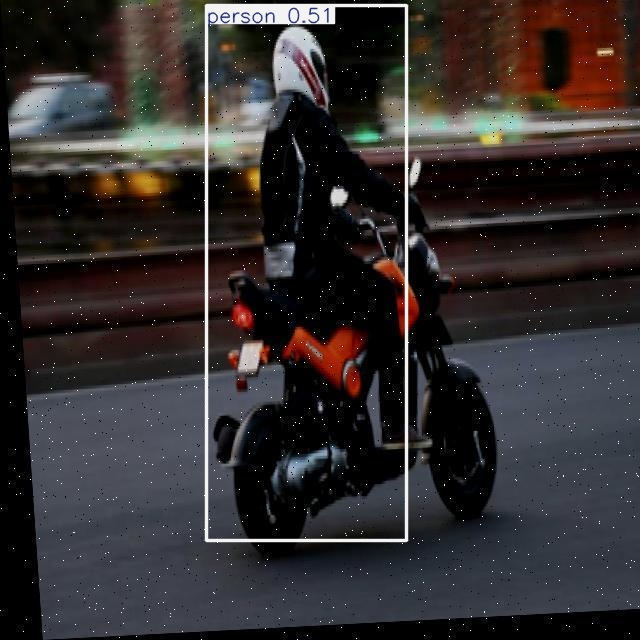

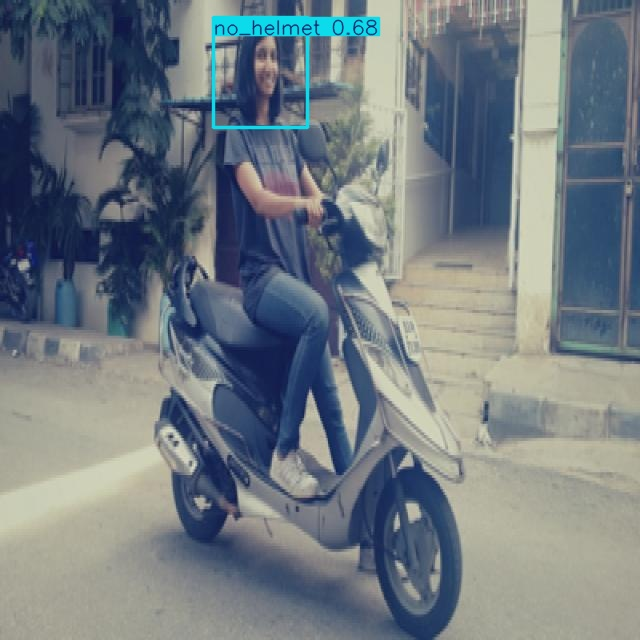

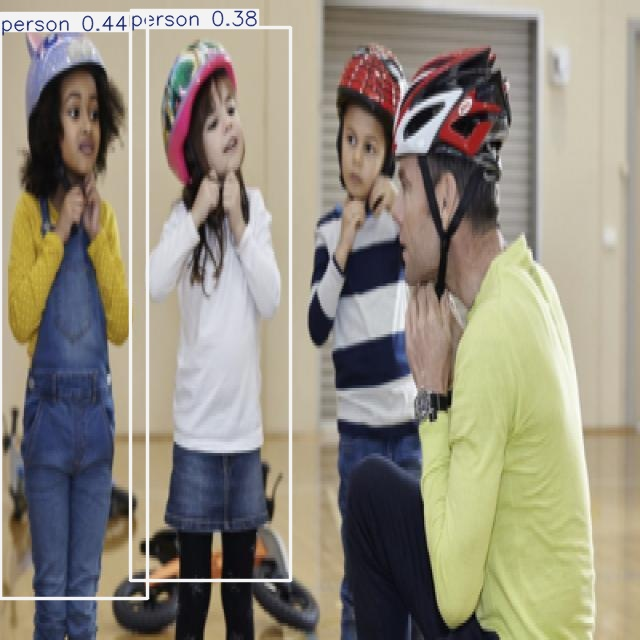

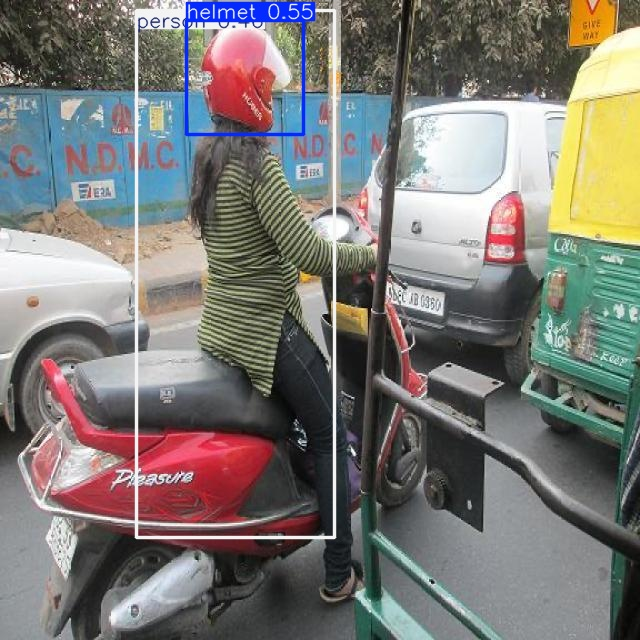

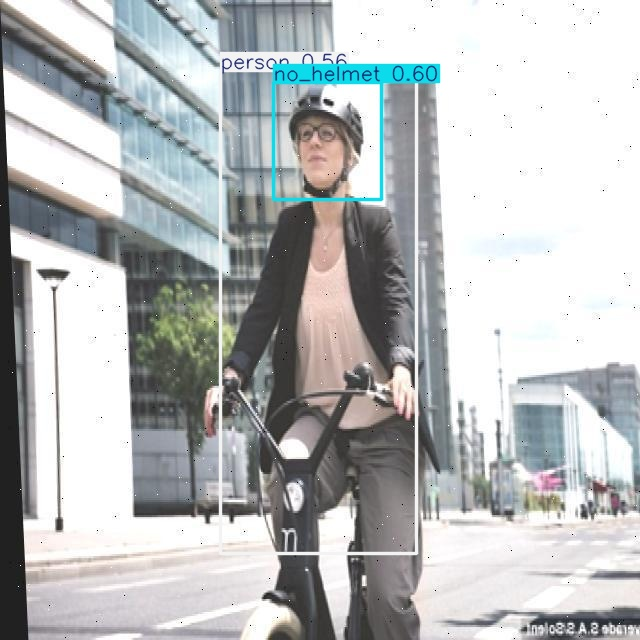

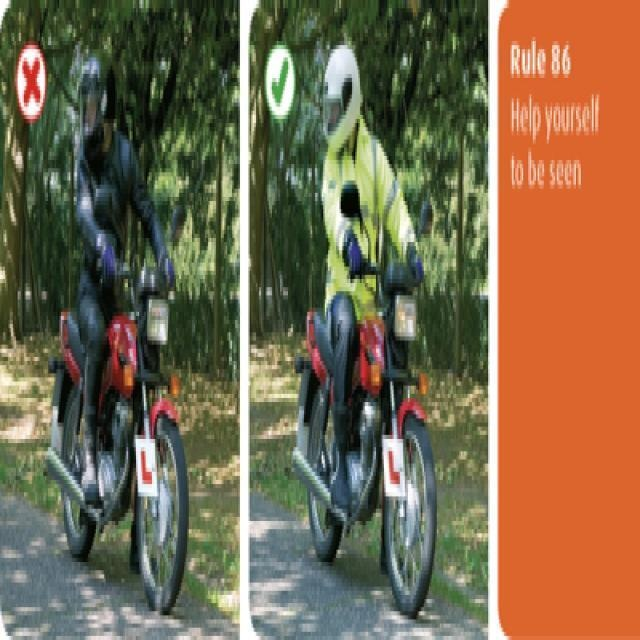

In [11]:
import sys
import os
import shutil
import subprocess

try:
    from ultralytics import YOLO
except ImportError:
    print("Installing ultralytics package...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "ultralytics"])
    from ultralytics import YOLO

import glob
from IPython.display import Image, display

# Redefining base paths
BASE = "/content/drive/MyDrive/cv_project"
DS = f"{BASE}/dataset"

# Force a Google Drive directory sync to refresh cache
for path_to_sync in [f"{BASE}/outputs/training_results/yolov8n_baseline/weights", f"{BASE}/models"]:
    if os.path.exists(path_to_sync):
        try:
            os.listdir(path_to_sync)
        except Exception:
            pass

weights_path = f"{BASE}/models/best.pt"
original_weights = f"{BASE}/outputs/training_results/yolov8n_baseline/weights/best.pt"

# Check and resolve missing best.pt weights
if not os.path.exists(weights_path):
    if os.path.exists(original_weights):
        print("Found weights at original path. Copying to target directory...")
        os.makedirs(os.path.dirname(weights_path), exist_ok=True)
        shutil.copy(original_weights, weights_path)
    else:
        raise FileNotFoundError(f"Could not find best.pt in '{weights_path}' or '{original_weights}'. Please ensure model training completed successfully.")

# Load the best trained model weights
model = YOLO(weights_path)

res = model.predict(source=f"{DS}/images/test", conf=0.35, save=True,
                    project=f"{BASE}/outputs/predictions", name="test_predictions", exist_ok=True)
pred_dir = f"{BASE}/outputs/predictions/test_predictions"
files = sorted(glob.glob(pred_dir+"/*"))
print("Prediction images saved:", len(files), "(need at least 15)")
for f in files[:15]: display(Image(f, width=500))

## 12. Error-analysis helper
Compares predictions vs ground-truth labels on the test set to list candidate errors. Review these images manually,
then fill the table in your report (need 10+).

In [12]:
def read_gt(path):
    if not os.path.exists(path): return []
    return [int(l.split()[0]) for l in open(path).read().strip().splitlines() if l.strip()]
rows = []
for r in res:
    name = os.path.splitext(os.path.basename(r.path))[0]
    gt = sorted(read_gt(f"{DS}/labels/test/{name}.txt"))
    pr = sorted(int(c) for c in r.boxes.cls.tolist())
    if gt != pr:
        miss = [CLASSES[c] for c in gt if c not in pr]
        extra = [CLASSES[c] for c in pr if c not in gt]
        rows.append({"image": name, "actual": [CLASSES[c] for c in gt], "predicted": [CLASSES[c] for c in pr],
                     "possible_false_negative": miss, "possible_false_positive/wrong_class": extra})
err = pd.DataFrame(rows); print(len(err), "images with differences"); display(err)
err.to_csv(f"{BASE}/outputs/error_candidates.csv", index=False)

14 images with differences


,image,actual,predicted,possible_false_negative,possible_false_positive/wrong_class
0,BikesHelmets133_png_jpg.rf.0fffb4d044cce0995e9...,"[no_helmet, person]",[no_helmet],[person],[]
1,BikesHelmets136_png_jpg.rf.c536bcf6fdfeaa241b4...,"[helmet, person]",[person],[helmet],[]
2,BikesHelmets139_png_jpg.rf.bfd9e25d7df1967237d...,"[helmet, person]",[person],[helmet],[]
3,BikesHelmets169_png_jpg.rf.40a414563b54016bbd2...,"[helmet, person]","[helmet, helmet, person]",[],[]
4,BikesHelmets17_png_jpg.rf.dc5c3eda8bbd8199ebdf...,"[helmet, person]",[person],[helmet],[]
5,BikesHelmets184_png_jpg.rf.7cb748e715173c98912...,"[helmet, person]",[],"[helmet, person]",[]
6,BikesHelmets201_png_jpg.rf.02f5292d23bce311e99...,"[no_helmet, person]",[],"[no_helmet, person]",[]
7,BikesHelmets242_png_jpg.rf.38d241cb7c581d50705...,"[helmet, person]","[person, person]",[helmet],[]
8,BikesHelmets246_png_jpg.rf.9157a04fa8992eaf0fc...,"[helmet, person]",[person],[helmet],[]
9,BikesHelmets251_png_jpg.rf.e7c7d3b98be1cd03cad...,"[no_helmet, person]",[no_helmet],[person],[]


## 13. (Optional) Video inference

In [13]:
# Upload a short video to Drive, set the path, and run:
# VIDEO = f"{BASE}/sample_video.mp4"
# model.predict(source=VIDEO, conf=0.35, save=True, project=f"{BASE}/outputs/demo_results", name="video", exist_ok=True)